# Mobility Aid Detection — Full Test and Robustness Evaluation

This notebook evaluates a trained ResNet18 model on the test set and checks how robust the model is against common image distortions.

The evaluation includes:

- Loading the test dataset
- Loading the trained model
- Running predictions on all test images
- Calculating accuracy, precision, recall, and F1-score
- Testing the model on brighter, noisy, and blurry images
- Saving all results as CSV files

The goal is to measure both the overall performance and the robustness of the model.

## 1. Import Libraries

This section imports all libraries required for data loading, image processing, model inference, evaluation, and visualization.

- `Path` is used to handle file and folder paths.
- `sys` is available for system-related settings, although it is not required by the evaluation steps used in this notebook.
- `time` is used to measure execution time.
- `numpy` and `pandas` are used for numerical operations and working with tabular data.
- `matplotlib` and `seaborn` are used to create visualisations, including the confusion matrix.
- `torch`, `torch.nn`, `DataLoader`, and `torchvision.models` are used to load and run the ResNet-18 model.
- `transforms` and `PIL` are used for image preprocessing and image loading.
- `cv2` is used for the Gaussian blur perturbation in the robustness test.
- `sklearn.metrics` provides metrics such as accuracy, precision, recall, F1-score, and the confusion matrix.

After running this cell, all required libraries are available for the
evaluation notebook.

In [25]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models, transforms

from PIL import Image
import cv2

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All required libraries are loaded.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

All required libraries are loaded.
PyTorch version: 2.15.0+cpu
CUDA available: False


## 2. Set Up the Project Path

This cell defines the local project directory and checks whether
the source-code folder, test CSV, trained model checkpoint, and
RGB image folder are available.

The project files were downloaded from the shared GitHub repository.

It then adds the project directory to Python's module search path
and imports `MobilityAidDataset` and `eval_transform` from `src`.

In [28]:
current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "src").is_dir()
        and (folder / "data").is_dir()
        and (folder / "models").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project directory not found. Start the notebook "
        "from the project directory or one of its subdirectories."
    )

print("Project directory:", PROJECT_ROOT)

required_paths = {
    "Source code directory": PROJECT_ROOT / "src",
    "Test CSV": PROJECT_ROOT / "data" / "test.csv",
    "Model checkpoint": PROJECT_ROOT / "models" / "best_resnet18.pth",
    "RGB image directory": PROJECT_ROOT / "Images_RGB",
}

for name, path in required_paths.items():
    print(f"{name}: {path.exists()}")

Project directory: C:\Users\Veyse\OneDrive\Desktop\AI Visualization\mobility-aids-resnet50-main\mobility-aids-resnet50-main
Source code directory: True
Test CSV: True
Model checkpoint: True
RGB image directory: True


In [29]:
import importlib

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

importlib.invalidate_caches()

from src import MobilityAidDataset, eval_transform

print("Project modules imported successfully.")
print("Project directory:", PROJECT_ROOT)
print("\nEvaluation transform:")
print(eval_transform)

Project modules imported successfully.
Project directory: C:\Users\Veyse\OneDrive\Desktop\AI Visualization\mobility-aids-resnet50-main\mobility-aids-resnet50-main

Evaluation transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 3. Load Test Data

This section loads the predefined test split from `data/test.csv`
and displays its structure, class distribution, and an example image path.

The CSV contains image paths, ground-truth labels, and additional
metadata. The test split contains 1952 samples:
- Class 0: 124 samples. The annotation contains other object categories
  but none of the four mobility-aid categories.
- Class 1: 1828 samples. The annotation contains at least one of:
  `wheelchair`, `walking_frame`, `crutches`, or `push_wheelchair`.

The ground-truth labels will later be compared with the model predictions.
The image files themselves are loaded in a subsequent step.


In [33]:
test_csv_path = PROJECT_ROOT / "data" / "test.csv"
test_df = pd.read_csv(test_csv_path)

required_columns = {"image_path", "label"}
missing_columns = required_columns - set(test_df.columns)

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {sorted(missing_columns)}"
    )

if test_df.empty:
    raise ValueError("The test CSV contains no samples.")

print("Test CSV loaded successfully.")
print("Number of test samples:", len(test_df))
print("Available columns:", test_df.columns.tolist())

print("\nClass distribution:")
print(test_df["label"].value_counts(dropna=False).sort_index())

print("\nFirst stored image path:")
print(test_df.iloc[0]["image_path"])

Test CSV loaded successfully.
Number of test samples: 1952
Available columns: ['image_id', 'image_path', 'categories', 'num_objects', 'label', 'timestamp', 'time_difference', 'sequence_id']

Class distribution:
label
0     124
1    1828
Name: count, dtype: int64

First stored image path:
..\Images_RGB\seq_1468843518.1616319190.png


## 4. Load the Trained Model

This section recreates the ResNet-18 architecture with two output classes and loads the trained weights from `models/best_resnet18.pth`.

The model is moved to the available device (GPU if available, otherwise CPU) and set to evaluation mode so that batch normalization uses its stored statistics during testing.



In [34]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_path = PROJECT_ROOT / "models" / "best_resnet18.pth"

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint, strict=True)
model = model.to(device)
model.eval()

print("Model loaded successfully.")
print("Checkpoint:", checkpoint_path)
print("Device:", device)
print("Number of output classes:", model.fc.out_features)
print("Evaluation mode:", not model.training)

Model loaded successfully.
Checkpoint: C:\Users\Veyse\OneDrive\Desktop\AI Visualization\mobility-aids-resnet50-main\mobility-aids-resnet50-main\models\best_resnet18.pth
Device: cpu
Number of output classes: 2
Evaluation mode: True


## 5. Check Image Paths 

This section checks whether all image files referenced in the test CSV
can be found locally.

Relative paths are checked against the project directory and its
`notebooks` subdirectory. The cell reports the number of files found
and lists examples of unresolved paths, if any.

The original CSV and `test_df` remain unchanged.

In [38]:
def resolve_image_path(stored_path):
    stored_path = Path(str(stored_path).replace("\\", "/"))

    if stored_path.is_absolute():
        candidates = [stored_path]
    else:
        candidates = [
            PROJECT_ROOT / stored_path,
            PROJECT_ROOT / "notebooks" / stored_path,
        ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()

    return None


resolved_paths = test_df["image_path"].apply(resolve_image_path)
missing_paths = resolved_paths.isna()

print("Number of test samples:", len(test_df))
print("Image files found:", int((~missing_paths).sum()))
print("Image files not found:", int(missing_paths.sum()))

if missing_paths.any():
    print("\nExamples of unresolved image paths:")
    print(test_df.loc[missing_paths, "image_path"].head().to_string(index=False))
else:
    print("\nAll test image paths were resolved successfully.")
    print("First resolved image path:", resolved_paths.iloc[0])

Number of test samples: 1952
Image files found: 1952
Image files not found: 0

All test image paths were resolved successfully.
First resolved image path: C:\Users\Veyse\OneDrive\Desktop\AI Visualization\mobility-aids-resnet50-main\mobility-aids-resnet50-main\Images_RGB\seq_1468843518.1616319190.png


## 6. Create the Test DataLoader

This section creates a copy of the test metadata with resolved local
image paths and builds the test dataset using `MobilityAidDataset`.

The evaluation transform resizes each image to 224 × 224 pixels,
converts it to a tensor, and applies ImageNet normalization.

The DataLoader loads samples in batches of 32 without shuffling.
The first batch is inspected to check image dimensions and data types:
- Images: `[32, 3, 224, 224]`, with dtype `torch.float32`.
- Labels: `[32]`, with dtype `torch.int64`.

The original CSV and `test_df` remain unchanged.

In [39]:
test_df_resolved = test_df.copy()
test_df_resolved["image_path"] = resolved_paths.apply(str)

test_dataset = MobilityAidDataset(
    test_df_resolved,
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(test_loader))

print("Test DataLoader created successfully.")
print("Number of test samples:", len(test_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Label tensor dtype:", labels.dtype)
print("Labels in the first batch:", labels.tolist())

Test DataLoader created successfully.
Number of test samples: 1952
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
Labels in the first batch: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 7. Evaluate the model

This section runs the trained model on all test images using the
evaluation preprocessing and compares each prediction with its
ground-truth label.

The results are stored in two lists:
- `all_preds`: the labels predicted by the model.
- `all_labels`: the ground-truth labels from the test dataset.

The cell reports accuracy and a classification report containing
precision, recall, and F1-score for each class.
The confusion matrix is visualized separately in the next section.

In [47]:
model.eval()

all_labels = []
all_preds = []

start_time = time.perf_counter()

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().tolist())
        all_preds.extend(predictions.cpu().tolist())

elapsed_time = time.perf_counter() - start_time

if len(all_preds) != len(test_dataset):
    raise RuntimeError(
        "The number of predictions does not match the test dataset size."
    )

print("Evaluation completed.")
print("Number of evaluated samples:", len(all_preds))
print(f"Duration: {elapsed_time:.1f} seconds")
print(f"Accuracy: {accuracy_score(all_labels, all_preds):.4f}")

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=[0, 1],
    target_names=["No annotated mobility aid", "Annotated mobility aid"],
    digits=4,
    zero_division=0
))

Evaluation completed.
Number of evaluated samples: 1952
Duration: 137.8 seconds
Accuracy: 0.9539

Classification report:
                           precision    recall  f1-score   support

No annotated mobility aid     0.6848    0.5081    0.5833       124
   Annotated mobility aid     0.9672    0.9841    0.9756      1828

                 accuracy                         0.9539      1952
                macro avg     0.8260    0.7461    0.7795      1952
             weighted avg     0.9493    0.9539    0.9507      1952



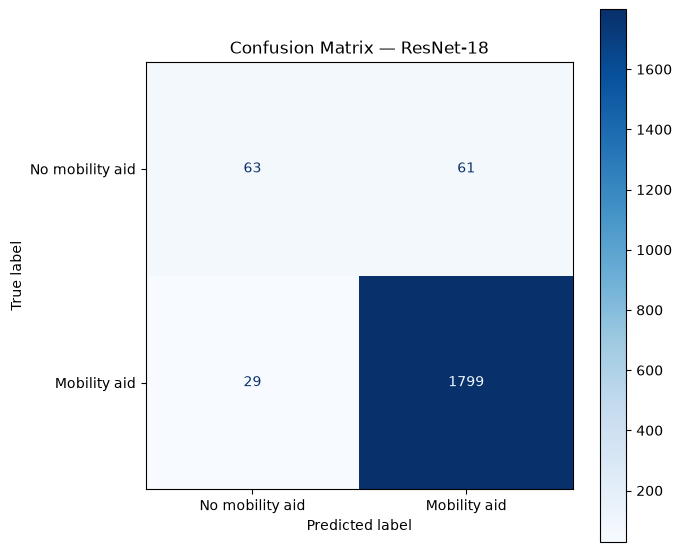

In [48]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_preds,
    labels=[0, 1],
    display_labels=[
        "No mobility aid",
        "Mobility aid"
    ],
    cmap="Blues",
    values_format="d",
    colorbar=True,
    ax=ax
)

ax.set_title("Confusion Matrix — ResNet-18")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

fig.tight_layout()
plt.show()

## 9. Robustness Test

This section tests the model under three types of image perturbations:

- Increased brightness
- Added Gaussian noise
- Gaussian blur

The original images serve as the reference condition. All image
variants use the same evaluation preprocessing as the standard test.

For each condition, predictions are compared with the ground-truth
labels. The results show how model performance changes under these
specific image perturbations.

In [49]:
noise_rng = np.random.default_rng(seed=42)


def make_brighter(image):
    array = np.asarray(image, dtype=np.float32)
    brighter = np.clip(array * 1.5 + 30, 0, 255).astype(np.uint8)
    return Image.fromarray(brighter)


def make_noisy(image):
    array = np.asarray(image, dtype=np.float32)
    noise = noise_rng.normal(loc=0, scale=25, size=array.shape)
    noisy = np.clip(array + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(noisy)


def make_blurry(image):
    array = np.asarray(image)
    blurry = cv2.GaussianBlur(array, (7, 7), 0)
    return Image.fromarray(blurry)


print("Image perturbation functions defined successfully.")
print("Brightness: pixel values multiplied by 1.5, then increased by 30.")
print("Noise: Gaussian noise with mean 0 and standard deviation 25.")
print("Blur: Gaussian blur with a 7 x 7 kernel.")

Image perturbation functions defined successfully.
Brightness: pixel values multiplied by 1.5, then increased by 30.
Noise: Gaussian noise with mean 0 and standard deviation 25.
Blur: Gaussian blur with a 7 x 7 kernel.


In [51]:
model.eval()
noise_rng = np.random.default_rng(seed=42)

robustness_results = []
start_time = time.perf_counter()

with torch.inference_mode():
    for position, row in enumerate(
        test_df_resolved.itertuples(index=False),
        start=1
    ):
        with Image.open(row.image_path) as image_file:
            image = image_file.convert("RGB")

        variants = [
            image,
            make_brighter(image),
            make_noisy(image),
            make_blurry(image)
        ]

        batch = torch.stack([
            eval_transform(variant) for variant in variants
        ]).to(device)

        predictions = model(batch).argmax(dim=1).cpu().tolist()
        true_label = int(row.label)

        result = {
            "image_id": row.image_id,
            "true_label": true_label
        }

        for condition, prediction in zip(
            ["original", "brighter", "noisy", "blurry"],
            predictions
        ):
            result[f"{condition}_prediction"] = prediction
            result[f"{condition}_correct"] = prediction == true_label

        robustness_results.append(result)

        if position % 100 == 0 or position == len(test_df_resolved):
            print(
                f"Processed {position}/{len(test_df_resolved)} images."
            )

robustness_df = pd.DataFrame(robustness_results)
elapsed_time = time.perf_counter() - start_time

print("\nRobustness test completed.")
print(f"Duration: {elapsed_time:.1f} seconds")

for condition in ["original", "brighter", "noisy", "blurry"]:
    correct = int(robustness_df[f"{condition}_correct"].sum())
    accuracy = robustness_df[f"{condition}_correct"].mean()

    print(
        f"{condition.title()}: {correct}/{len(robustness_df)} correct "
        f"| Accuracy: {accuracy:.4f}"
    )

Processed 100/1952 images.
Processed 200/1952 images.
Processed 300/1952 images.
Processed 400/1952 images.
Processed 500/1952 images.
Processed 600/1952 images.
Processed 700/1952 images.
Processed 800/1952 images.
Processed 900/1952 images.
Processed 1000/1952 images.
Processed 1100/1952 images.
Processed 1200/1952 images.
Processed 1300/1952 images.
Processed 1400/1952 images.
Processed 1500/1952 images.
Processed 1600/1952 images.
Processed 1700/1952 images.
Processed 1800/1952 images.
Processed 1900/1952 images.
Processed 1952/1952 images.

Robustness test completed.
Duration: 486.2 seconds
Original: 1862/1952 correct | Accuracy: 0.9539
Brighter: 1825/1952 correct | Accuracy: 0.9349
Noisy: 1849/1952 correct | Accuracy: 0.9472
Blurry: 1813/1952 correct | Accuracy: 0.9288


In [53]:
robustness_summary = pd.DataFrame([
    {
        "Condition": condition,
        "Correct predictions": int(robustness_df[f"{condition}_correct"].sum()),
        "Total images": len(robustness_df),
        "Accuracy": robustness_df[f"{condition}_correct"].mean(),
        "Accuracy change (percentage points)": (
            robustness_df[f"{condition}_correct"].mean()
            - robustness_df["original_correct"].mean()
        ) * 100
    }
    for condition in ["original", "brighter", "noisy", "blurry"]
])

robustness_summary["Accuracy"] = robustness_summary["Accuracy"].round(4)
robustness_summary["Accuracy change (percentage points)"] = (
    robustness_summary["Accuracy change (percentage points)"].round(2)
)

robustness_summary

,Condition,Correct predictions,Total images,Accuracy,Accuracy change (percentage points)
0,original,1862,1952,0.9539,0.00
1,brighter,1825,1952,0.9349,-1.90
2,noisy,1849,1952,0.9472,-0.67
3,blurry,1813,1952,0.9288,-2.51


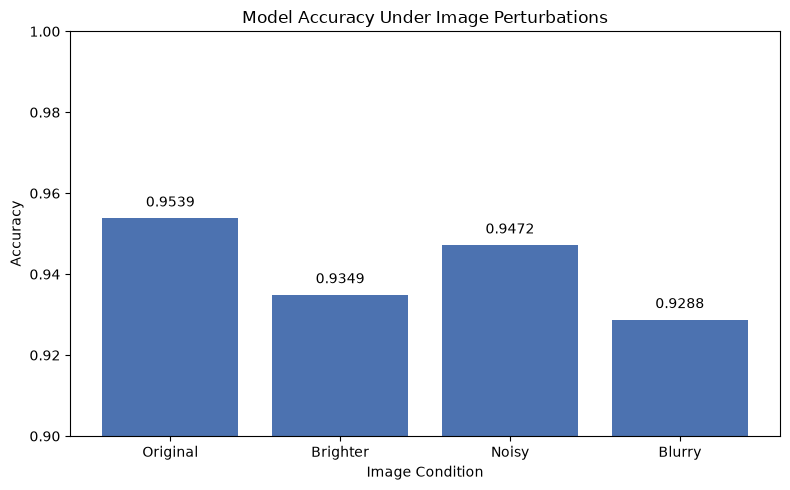

In [54]:
condition_labels = [
    "Original",
    "Brighter",
    "Noisy",
    "Blurry"
]

condition_columns = [
    "original_correct",
    "brighter_correct",
    "noisy_correct",
    "blurry_correct"
]

accuracies = [
    robustness_df[column].mean()
    for column in condition_columns
]

plt.figure(figsize=(8, 5))
bars = plt.bar(condition_labels, accuracies, color="#4C72B0")

plt.title("Model Accuracy Under Image Perturbations")
plt.xlabel("Image Condition")
plt.ylabel("Accuracy")
plt.ylim(0.90, 1.00)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.002,
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Robustness Test Results

The model achieved an accuracy of 95.39% on the original test images,
matching the previous evaluation result.

Accuracy decreased under all three tested perturbations:

- Increased brightness: 93.49%, a decrease of 1.90 percentage points.
- Gaussian noise: 94.72%, a decrease of 0.67 percentage points.
- Gaussian blur: 92.88%, a decrease of 2.51 percentage points.

Among the tested conditions, Gaussian noise produced the smallest
accuracy decrease, while Gaussian blur produced the largest decrease.
The model maintained an accuracy above 92% in every condition.

These findings apply to the specific perturbation settings and test
images used here. They do not establish robustness to stronger
perturbations, combinations of perturbations, or other image changes.